# Assignment 4 – Part 3: Investigate the mechanisms

Start med de valgte konfigurasjonene fra [Part 2](02_part2_synthesis.ipynb).
Vi bruker setting B (native MsPacMan, sticky actions 0.25, poengøkning som belønning)
og samme observasjoner, agenter, interaksjonsbudsjett og fem treningsfrø.
Hver ny konfigurasjon trenes fra start. Den gjeldende konfigurasjonen er kontrollen
i hvert forsøk, og den valgte verdien videreføres innen samme algoritme.

Velg prosjektets Python-kjerne med pakkene fra `requirements.txt`.
Sett `RUN_THROUGH = "epsilon"` i oppsettscellen og kjør notebooken ovenfra.
Utvid deretter `RUN_THROUGH` til neste steg. Ferdige modellkjøringer med samme
konfigurasjon, kildefiler og programvaremiljø gjenbrukes.
`QUICK_CHECK = True` gir en separat teknisk sjekk med ett frø og 2 048 interaksjoner.

In [17]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "IT3212 - Assignment 4.pdf").is_file()).resolve()
sys.path.insert(0, str(ROOT / "notebooks/assignment4"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from part3_experiments import PART2_BASELINE, evaluate_locked, experiment_protocol, run_sweep, study_folder

# Kjør til og med steget som er valgt her. None viser bare planen.
RUN_THROUGH = "epochs"
QUICK_CHECK = False
WORKERS = 2
RUN_DIAGNOSTIC = True
RUN_HELD_OUT = True

STAGES = ["epsilon", "discount", "entropy", "learning_rate", "epochs"]
protocol = experiment_protocol(
    setting="B",
    budget=262_144,
    training_seeds=(17, 29, 101, 314, 2718),
    development_episodes=10,
    quick_check=QUICK_CHECK,
)
q = PART2_BASELINE["Q-learning"].copy()
ppo = PART2_BASELINE["PPO"].copy()

stop_after = -1 if RUN_THROUGH is None else STAGES.index(RUN_THROUGH)
print(f"Setting {protocol['setting']} | {protocol['budget']:,} interaksjoner per modell")
print("Treningsfrø", protocol["training_seeds"])
print("Resultater", study_folder(protocol).relative_to(ROOT))
display(pd.DataFrame(PART2_BASELINE).T)

Setting B | 262,144 interaksjoner per modell
Treningsfrø [17, 29, 101, 314, 2718]
Resultater results\assignment4\part3\study\e8c0c6a8f4071325


,alpha,gamma,epsilon_start,epsilon_end,epsilon_decay_fraction,entropy_scale,learning_rate_scale,n_epochs
Q-learning,0.15,0.995,1.0,0.05,0.8,NaN,NaN,NaN
PPO,NaN,0.995,NaN,NaN,NaN,1.0,1.0,6.0


## Sammenligning og valg

Evalueringen er fryst. Q velger grådig med seedet tilfeldig valg ved like Q-verdier,
og PPO velger handlingen med høyest sannsynlighet. Utviklingsepisoder kjøres ved
0 og hver 65 536 interaksjoner, inkludert endepunktet. For hvert frø velges
checkpoint etter suksessandel, rå poeng og tidligste checkpoint ved likhet.
Steg 0 vises i kurvene.

Kandidatene rangeres etter gjennomsnittlig utviklingssuksess over treningsfrø,
deretter gjennomsnittlige rå poeng. Ved likhet beholdes kontrollverdien hvis den
deler førsteplassen. Hvert frø teller én gang. Evalueringsfrøene i siste celle
holdes tilbake til innstillingene er låst.

In [18]:
def compare(stage, algorithm, incumbent, parameter, alternatives):
    if STAGES.index(stage) > stop_after:
        return incumbent

    chosen, ranking, per_seed, learning, folder = run_sweep(
        protocol, algorithm, incumbent, parameter, alternatives, workers=WORKERS
    )
    # Vis suksess i prosent og endring mot kontroll i prosentpoeng.
    overview = ranking.copy()
    for column in ("success_mean", "success_sd", "failure_mean", "paired_success_delta"):
        overview[column] *= 100
    display(overview.round(2))
    display((100 * per_seed.pivot(index="training_seed", columns="value",
                                 values="success_rate")).round(1))
    print(f"Valgt {parameter} = {chosen[parameter]}")
    print(folder.relative_to(ROOT))

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
    for ax, metric, ylabel, scale in zip(
        axes, ["success_rate", "mean_score"], ["Suksess (%)", "Rå poeng"], [100, 1]
    ):
        summary = learning.groupby(["value", "interactions"])[metric].agg(["mean", "std"])
        for value, points in summary.groupby(level="value"):
            points = points.droplevel("value")
            mean = scale * points["mean"]
            sd = scale * points["std"]
            lower, upper = mean - sd, mean + sd
            if metric == "success_rate":
                lower, upper = lower.clip(lower=0), upper.clip(upper=100)
            ax.plot(points.index, mean, marker="o", label=f"{value:g}")
            ax.fill_between(points.index, lower, upper, alpha=0.12)
        ax.set(xlabel="Treningsinteraksjoner", ylabel=ylabel)
        ax.grid(alpha=0.2)
    axes[0].legend(title=parameter)
    fig.suptitle(f"{folder.name} · hver linje er et frøsnitt, bånd viser ±1 SD")
    plt.show()
    return chosen

## 1. Epsilon for Q-learning

Test sluttverdiene 0,01, 0,05 og 0,15. Alle starter på 1,0 og går lineært ned
over de første 80 % av budsjettet. Hvilken mengde tilfeldig utforskning mot
slutten gir best grådig policy? Sammenlign også antall besøkte Q-tilstander
(`q_states` i kurveloggen) og om gevinsten går igjen på tvers av frø.

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_4af1ac6d64ca7a2f\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assign

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
1,0.05,5,42.0,21.68,1661.4,1661.4,58.0,625.30,718.87,225.45,0.0,True
2,0.15,5,26.0,18.17,1513.6,1513.6,74.0,589.49,801.23,211.72,-16.0,False
0,0.01,5,22.0,13.04,1392.8,1392.8,78.0,711.17,707.07,226.24,-20.0,False


value,0.01,0.05,0.15
training_seed,,,
17,30.0,30.0,10.0
29,10.0,30.0,40.0
101,10.0,30.0,10.0
314,40.0,40.0,20.0
2718,20.0,80.0,50.0


Valgt epsilon_end = 0.05
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\Q-learning_epsilon_end_44e262f0407f6f5a


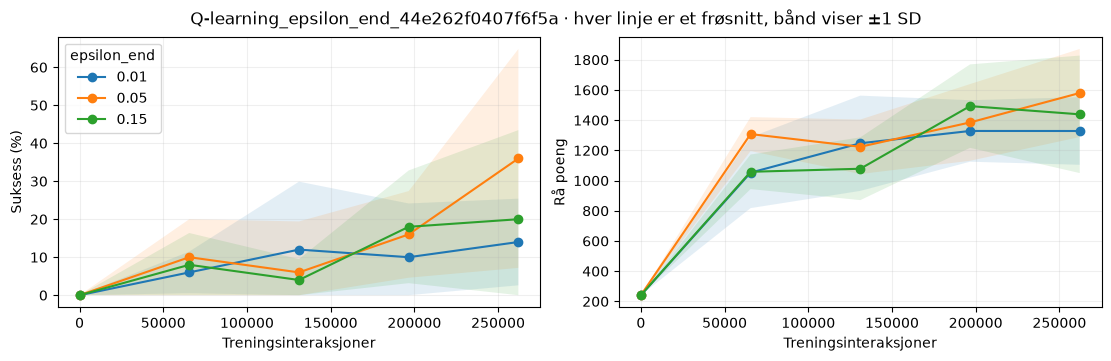

In [19]:
q = compare("epsilon", "Q-learning", PART2_BASELINE["Q-learning"], "epsilon_end", [0.01, 0.15])

## 2. Diskonteringsfaktor

Test 0,990, 0,995 og 0,999 for hver metode separat. Q beholder valgt epsilon.
Høyere gamma legger mer vekt på senere belønning. Se på både poeng,
måloppnåelse og lengden på vellykkede episoder.

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_4b0adbd9d0eb757d\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assign

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
1,1.00,5,42.0,21.68,1661.4,1661.4,58.0,625.30,718.87,225.45,0.0,True
2,1.00,5,42.0,8.37,1657.2,1657.2,58.0,524.51,735.96,243.22,0.0,False
0,0.99,5,36.0,20.74,1662.8,1662.8,64.0,617.60,712.00,206.46,-6.0,False


value,0.990,0.995,0.999
training_seed,,,
17,20.0,30.0,30.0
29,40.0,30.0,40.0
101,20.0,30.0,50.0
314,70.0,40.0,50.0
2718,30.0,80.0,40.0


Valgt gamma = 0.995
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\Q-learning_gamma_a7dfc09b21386364


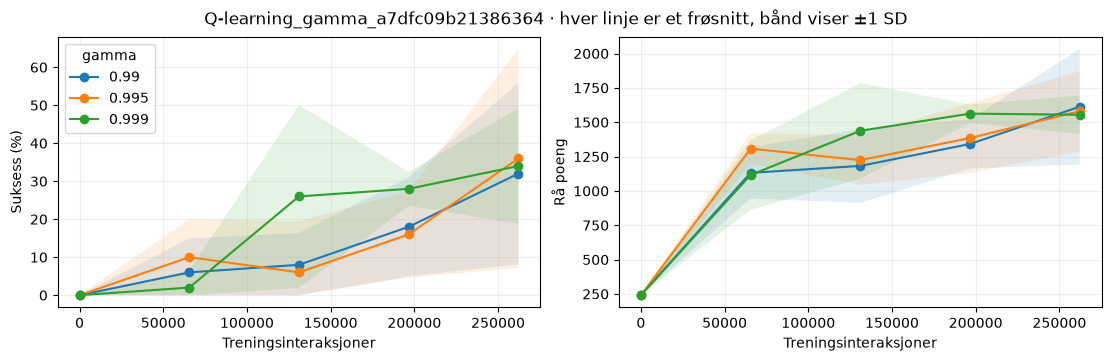

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_1cf6d6f0f2e8657a\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
1,1.00,5,74.0,27.02,1931.2,1931.2,26.0,586.59,891.56,267.31,0.0,True
0,0.99,5,54.0,20.74,1771.4,1771.4,46.0,661.08,791.98,251.78,-20.0,False
2,1.00,5,42.0,25.88,1834.4,1834.4,58.0,608.52,930.82,234.70,-32.0,False


value,0.990,0.995,0.999
training_seed,,,
17,40.0,30.0,0.0
29,80.0,90.0,50.0
101,50.0,80.0,70.0
314,30.0,100.0,40.0
2718,70.0,70.0,50.0


Valgt gamma = 0.995
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\PPO_gamma_58c70af0b0ce6aa4


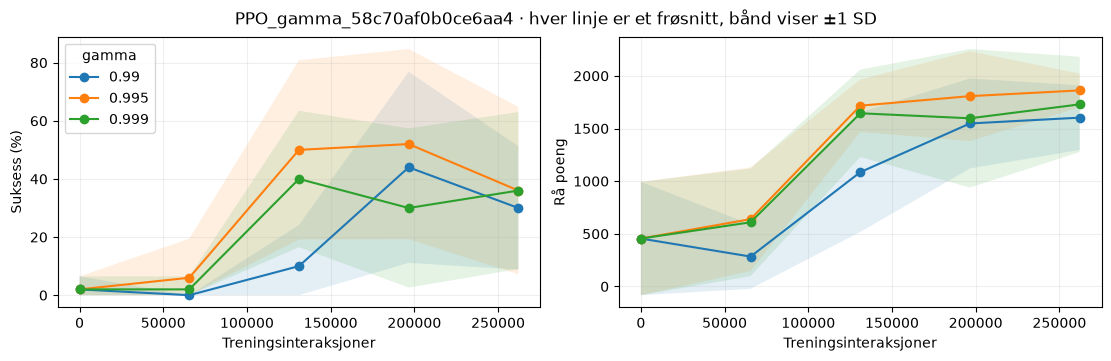

In [20]:
q = compare("discount", "Q-learning", q, "gamma", [0.990, 0.999])
ppo = compare("discount", "PPO", PART2_BASELINE["PPO"], "gamma", [0.990, 0.999])

## 3. Entropikoeffisient for PPO

Skaler Part 2-planen (0,020 til 0,002) med 0, 1 eller 2. Behold valgt gamma.
Sammenlign læringskurvene for å se om en sterkere oppmuntring til ulike
handlinger under trening gir en bedre fryst policy.

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_8d1ce00dd6d355b3\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
1,1.0,5,74.0,27.02,1931.2,1931.2,26.0,586.59,891.56,267.31,0.0,True
0,0.0,5,66.0,35.78,1889.4,1889.4,34.0,479.39,927.24,227.88,-8.0,False
2,2.0,5,58.0,20.49,1884.4,1884.4,42.0,602.73,869.82,220.96,-16.0,False


value,0.0,1.0,2.0
training_seed,,,
17,100.0,30.0,60.0
29,100.0,90.0,90.0
101,70.0,80.0,40.0
314,20.0,100.0,60.0
2718,40.0,70.0,40.0


Valgt entropy_scale = 1.0
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\PPO_entropy_scale_540ec07d218ba7dc


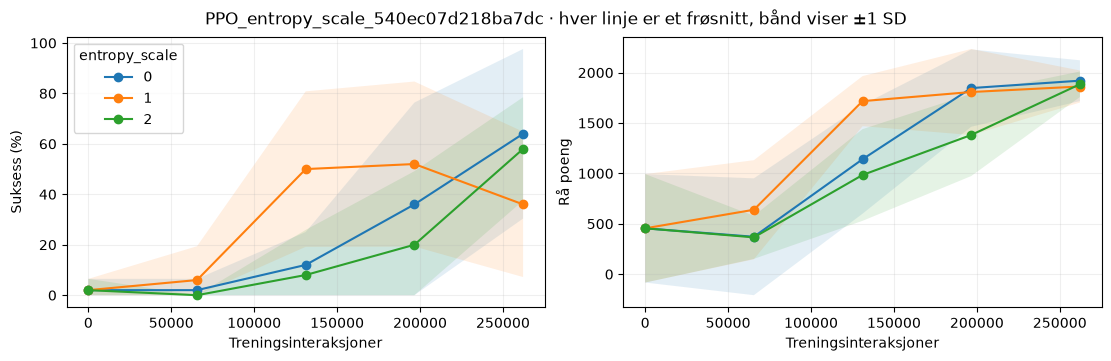

In [21]:
ppo = compare("entropy", "PPO", ppo, "entropy_scale", [0.0, 2.0])

## 4. Læringsrate

Test 0,075, 0,15 og 0,30 for Q. For PPO varierer vi størrelsen på den
lineære planen (0,00030 til 0,00005) med faktor 0,5, 1 eller 2.
Se etter treg tidlig forbedring, fall mellom checkpoints og variasjon mellom frø.

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_c01be250974f6cbb\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assign

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
1,0.15,5,42.0,21.68,1661.4,1661.4,58.0,625.30,718.87,225.45,0.0,True
0,0.08,5,22.0,16.43,1432.2,1432.2,78.0,785.74,744.85,228.27,-20.0,False
2,0.30,5,18.0,8.37,1358.6,1358.6,82.0,748.47,753.17,215.38,-24.0,False


value,0.075,0.150,0.300
training_seed,,,
17,10.0,30.0,30.0
29,20.0,30.0,10.0
101,50.0,30.0,20.0
314,20.0,40.0,20.0
2718,10.0,80.0,10.0


Valgt alpha = 0.15
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\Q-learning_alpha_7c1bd8c148ebbb73


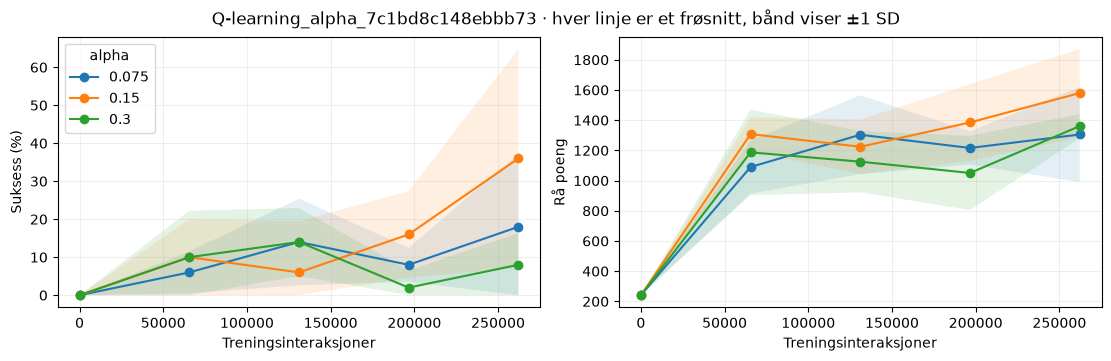

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_6838d32fa88a693f\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
2,2.0,5,76.0,19.49,1996.8,1996.8,24.0,520.65,938.73,247.38,2.0,False
1,1.0,5,74.0,27.02,1931.2,1931.2,26.0,586.59,891.56,267.31,0.0,True
0,0.5,5,30.0,40.62,1348.0,1348.0,70.0,567.06,887.18,247.66,-44.0,False


value,0.5,1.0,2.0
training_seed,,,
17,10.0,30.0,70.0
29,100.0,90.0,70.0
101,10.0,80.0,50.0
314,30.0,100.0,100.0
2718,0.0,70.0,90.0


Valgt learning_rate_scale = 2.0
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\PPO_learning_rate_scale_c153bc0b479a9167


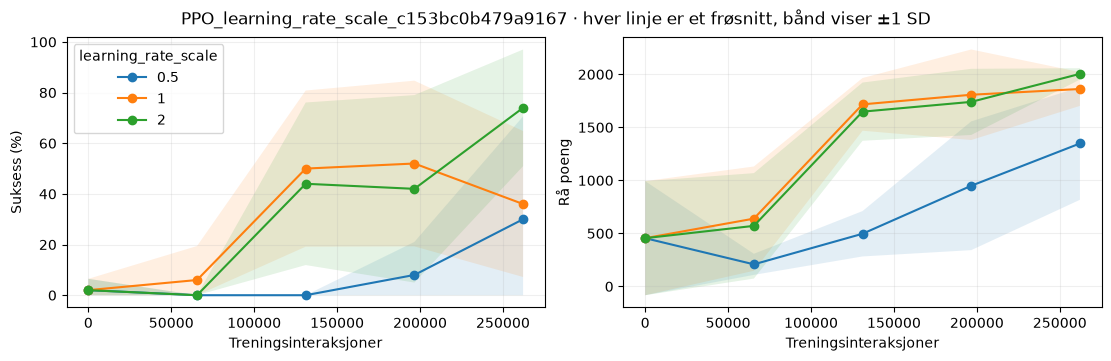

In [22]:
q = compare("learning_rate", "Q-learning", q, "alpha", [0.075, 0.30])
ppo = compare("learning_rate", "PPO", ppo, "learning_rate_scale", [0.5, 2.0])

## 5. PPO-epoker per rollout

Test maksimalt 3, 6 og 12 epoker med samme rollout på 2 048 interaksjoner.
KL-grensen kan stoppe en oppdatering tidlig. `ppo_epochs_started` i kurveloggen
viser hvor mange epoker SB3 har startet.

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_7a0d1ccd9877c189\seed_29
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_7a0d1ccd9877c189\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_7a0d1ccd9877c189\seed_101
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_7a0d1ccd9877c189\seed_314
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_7a0d1ccd9877c189\seed_2718
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_134dde9c1ff15bd5\seed_17
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study

,value,training_seeds,success_mean,success_sd,score_mean,return_mean,failure_mean,success_length,failure_length,train_seconds,paired_success_delta,incumbent
2,12,5,96.0,8.94,2031.6,2031.6,4.0,487.28,553.00,249.58,20.0,False
0,3,5,88.0,16.43,2013.8,2013.8,12.0,521.60,893.00,223.64,12.0,False
1,6,5,76.0,19.49,1996.8,1996.8,24.0,520.65,938.73,247.38,0.0,True


value,3,6,12
training_seed,,,
17,60.0,70.0,80.0
29,100.0,70.0,100.0
101,100.0,50.0,100.0
314,90.0,100.0,100.0
2718,90.0,90.0,100.0


Valgt n_epochs = 12
results\assignment4\part3\study\e8c0c6a8f4071325\sweeps\PPO_n_epochs_b45bbccce63e7f52


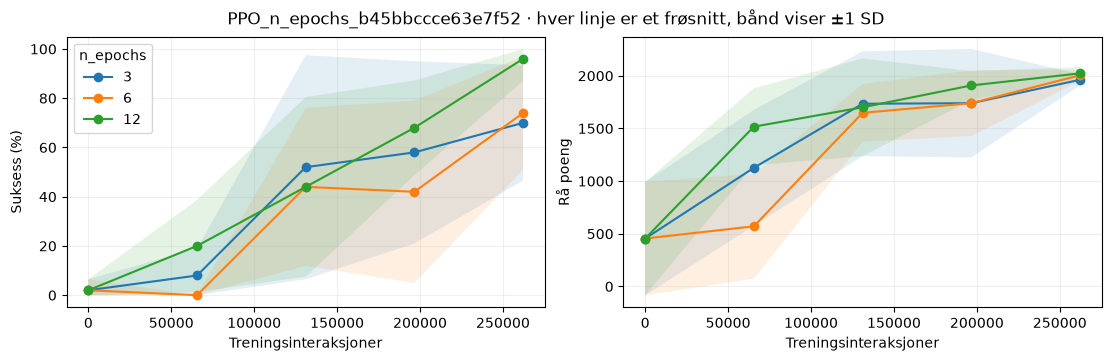

,alpha,gamma,epsilon_start,epsilon_end,epsilon_decay_fraction,entropy_scale,learning_rate_scale,n_epochs
Q-learning,0.15,0.995,1.0,0.05,0.8,NaN,NaN,NaN
PPO,NaN,0.995,NaN,NaN,NaN,1.0,2.0,12.0


In [23]:
ppo = compare("epochs", "PPO", ppo, "n_epochs", [3, 12])
display(pd.DataFrame({"Q-learning": q, "PPO": ppo}).T)

## 6. Diagnostikk av tidlig læring

Part 1 predikerte at Q-learning lærer raskest med lite treningsdata. Ved
65 536 interaksjoner fikk Q-learning 10 %, PPO med 6 epoker 0 % og PPO med
12 epoker 20 % suksess på utviklingsepisodene. For frø 17 ledet Q-learning
med 20 % mot 0 % for begge PPO-variantene.

Vi tester om forskjellen holder på nye episoder. Mulige forklaringer er
at ekstra oppdateringer per rollout hjalp PPO tidlig, eller at de ti
utviklingsepisodene per frø ga en ustabil rangering. Vi låser checkpointet
til 65 536 interaksjoner for alle tre grupper. PPO-konfigurasjonene skiller
seg bare i antall epoker. Sammenlign de fem frøene parvis, med 50 nye
evalueringsepisoder per modell og samme evalueringsfrø i alle grupper.

Hvis PPO med 12 epoker fortsatt slår både PPO med 6 epoker og Q-learning,
har vi støtte for at PPO-oppsettet kan snu den tidlige rangeringen.
Evalueringsforsøket tester om rangeringen gjentas med flere episoder.
Bruk `RUN_DIAGNOSTIC = True` for å kjøre dette steget med de lagrede modellene.

In [24]:
import json
from tempfile import TemporaryDirectory

import torch
from part3_experiments import job_folder, record_id
from ppo import FrozenPolicy
from q_learning import TabularQ, evaluate, require, sha, verify_sources, write_json


def early_checkpoint_diagnostic(protocol, q_settings, ppo_settings):
    point = 65_536
    seeds = list(range(1_370_000, 1_370_050))
    other_seeds = protocol["development_seeds"] + protocol["evaluation_seeds"]
    require(point in protocol["checkpoints"], f"Missing checkpoint at {point:,} interactions.")
    require(not set(seeds).intersection(other_seeds), "Diagnostic seeds overlap other evaluation phases.")
    verify_sources(protocol["source_hashes"])
    variants = [
        ("Q-learning", "Q-learning", q_settings),
        ("PPO-6", "PPO", dict(ppo_settings, n_epochs=6)),
        ("PPO-12", "PPO", dict(ppo_settings, n_epochs=12)),
    ]

    jobs = []
    for label, algorithm, settings in variants:
        for seed in protocol["training_seeds"]:
            run = job_folder(protocol, algorithm, settings, seed)
            require((run / "completed.json").is_file(), f"Complete the training run first: {run}")
            curves = pd.read_csv(run / "curves.csv")
            rows = curves.loc[curves["interactions"] == point]
            require(len(rows) == 1, f"Missing or duplicate checkpoint in {run}")
            checkpoint = rows.iloc[0]
            model = run / checkpoint["model"]
            require(sha(model) == checkpoint["model_sha256"], f"Checkpoint has changed: {model}")
            jobs.append(dict(label=label, algorithm=algorithm, settings=settings, training_seed=seed,
                             model=model.relative_to(ROOT).as_posix(), model_sha256=sha(model)))

    lock = dict(experiment="early_checkpoint_v1", interactions=point, setting=protocol["setting"],
                evaluation_seeds=seeds, policy=protocol["policy"], jobs=jobs)
    output = study_folder(protocol) / f"diagnostic_early_{record_id(lock)}"
    output.mkdir(parents=True, exist_ok=True)
    lock_path = output / "locked.json"
    if lock_path.is_file():
        require(json.loads(lock_path.read_text(encoding="utf-8")) == lock, "Diagnostic lock has changed.")
    else:
        write_json(lock_path, lock)

    torch.set_num_threads(protocol["numerical_threads"])
    per_seed = []
    for job in jobs:
        label, seed = job["label"], job["training_seed"]
        destination = output / f"{label}_{seed}.csv"
        if not destination.is_file():
            print(f"Evaluerer {label}, treningsfrø {seed}", flush=True)
            model = ROOT / job["model"]
            require(sha(model) == job["model_sha256"], f"Checkpoint has changed: {model}")
            loader = TabularQ.load if job["algorithm"] == "Q-learning" else FrozenPolicy.load
            with TemporaryDirectory(prefix=".evaluation_", dir=output) as staging:
                staging = Path(staging)
                evaluate(loader(model), job["algorithm"], protocol["setting"], seeds, staging, "episodes")
                (staging / "episodes.csv").replace(destination)
        episodes = pd.read_csv(destination)
        require(episodes["evaluation_seed"].tolist() == seeds, f"Unexpected episodes in {destination}")
        require(episodes["success"].eq(episodes["score"].ge(2000)).all()
                and episodes["censored"].eq(0).all(), f"Unexpected outcomes in {destination}")
        per_seed.append(dict(configuration=label, training_seed=seed, episodes=len(episodes),
                             success_pct=100 * episodes["success"].mean(),
                             mean_score=episodes["score"].mean(), model=job["model"]))
    frame = pd.DataFrame(per_seed)
    frame.to_csv(output / "per_seed.csv", index=False)
    return frame, output


if RUN_DIAGNOSTIC and RUN_THROUGH == "epochs" and not QUICK_CHECK:
    diagnostic, diagnostic_folder = early_checkpoint_diagnostic(protocol, q, ppo)
    paired = diagnostic.pivot(index="training_seed", columns="configuration", values="success_pct")
    paired["12 minus 6 (prosentpoeng)"] = paired["PPO-12"] - paired["PPO-6"]
    paired["12 minus Q (prosentpoeng)"] = paired["PPO-12"] - paired["Q-learning"]
    display(paired.round(1))
    display(diagnostic.groupby("configuration")["success_pct"].agg(["mean", "std"]).round(1))
    print(diagnostic_folder.relative_to(ROOT))

configuration,PPO-12,PPO-6,Q-learning,12 minus 6 (prosentpoeng),12 minus Q (prosentpoeng)
training_seed,,,,,
17,2.0,0.0,8.0,2.0,-6.0
29,48.0,0.0,8.0,48.0,40.0
101,16.0,0.0,4.0,16.0,12.0
314,68.0,0.0,4.0,68.0,64.0
2718,14.0,0.0,4.0,14.0,10.0


,mean,std
configuration,,
PPO-12,29.6,27.4
PPO-6,0.0,0.0
Q-learning,5.6,2.2


results\assignment4\part3\study\e8c0c6a8f4071325\diagnostic_early_3142fac3111db314


## Fryst bekreftelse

Når alle fem steg er kjørt, sett `RUN_HELD_OUT = True` og kjør notebooken
med `RUN_THROUGH = "epochs"`. Dette sammenligner Part 2-oppsettet vi trente
på nytt her med sluttvalgene, på 200 separate episoder per frø og konfigurasjon.
Rapportér variasjon over frø. Hold valg av modell og parametere låst før evalueringen.

Konfigurasjoner, frø, programvareversjoner, checkpoints og rå episodelogger
ligger under resultatmappen fra oppsettet. `selection.json` i hver sammenligning
peker til kildekjøringene. `per_seed.csv` gjør det mulig å se hvilke frø som
driver forskjellen. Ved rask sjekk brukes én evalueringsepisode per modell.

In [25]:
if RUN_HELD_OUT:
    if RUN_THROUGH != "epochs":
        raise ValueError('Fullfør alle sammenligninger med RUN_THROUGH = "epochs" først.')
    held_out = evaluate_locked(protocol, {"Q-learning": q, "PPO": ppo}, workers=WORKERS)
    display(held_out.groupby(["algorithm", "label"]).agg(
        success_mean=("success_rate", "mean"), success_sd=("success_rate", "std"),
        failure_mean=("failure_rate", "mean"), return_mean=("mean_return", "mean"),
        success_length=("success_length", "mean"), failure_length=("failure_length", "mean"),
        train_seconds=("training_seconds", "mean"), eval_seconds=("evaluation_seconds", "mean"),
        interactions=("training_interactions", "first"),
    ).round(3))
    display(held_out[["algorithm", "label", "training_seed", "success_rate", "run_id"]])

C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_29\held_out
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_17\held_out
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_101\held_out
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_314\held_out
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\Q-learning_1e35db1b778e5790\seed_2718\held_out
C:\Users\Elling pc2\Desktop\Skole\Datadriven Software\Assignment4-kopi\results\assignment4\part3\study\e8c0c6a8f4071325\PPO_50ed71056d1034d6\seed_17\held_out
C:\Users\Elli

success_mean  success_sd  failure_mean  return_mean  \
algorithm  label                                                           
PPO        baseline         0.702       0.161         0.298      1934.71   
           selected         0.902       0.080         0.098      2008.18   
Q-learning baseline         0.313       0.210         0.687      1572.10   
           selected         0.313       0.210         0.687      1572.10   

                     success_length  failure_length  train_seconds  \
algorithm  label                                                     
PPO        baseline         597.000         894.500        267.311   
           selected         496.837         756.010        249.581   
Q-learning baseline         632.234         731.432        225.452   
           selected         632.234         731.432        225.452   

                     eval_seconds  interactions  
algorithm  label                                 
PPO        baseline       160.417        262144  
           selected       121.589        262144  
Q-learning baseline       105.139        262144  
           selected       105.139        262144

,algorithm,label,training_seed,success_rate,run_id
0,Q-learning,baseline,17,0.205,results\assignment4\part3\study\e8c0c6a8f40713...
1,Q-learning,baseline,29,0.270,results\assignment4\part3\study\e8c0c6a8f40713...
2,Q-learning,baseline,101,0.060,results\assignment4\part3\study\e8c0c6a8f40713...
3,Q-learning,baseline,314,0.420,results\assignment4\part3\study\e8c0c6a8f40713...
4,Q-learning,baseline,2718,0.610,results\assignment4\part3\study\e8c0c6a8f40713...
5,PPO,baseline,17,0.470,results\assignment4\part3\study\e8c0c6a8f40713...
6,PPO,baseline,29,0.770,results\assignment4\part3\study\e8c0c6a8f40713...
7,PPO,baseline,101,0.725,results\assignment4\part3\study\e8c0c6a8f40713...
8,PPO,baseline,314,0.905,results\assignment4\part3\study\e8c0c6a8f40713...
9,PPO,baseline,2718,0.640,results\assignment4\part3\study\e8c0c6a8f40713...


## Oppfølging etter målingene

Knytt resultatene til den opprinnelige [Part 1-prediksjonen](../../reports/assignment4/Sections/01_predictions.tex).
Bruk resultatet fra det diagnostiske forsøket og trekk fram frøet som bryter
med gjennomsnittsmønsteret. Oppgi kildekjøringer for sammenligningen og diagnostikken.

Codex foreslo verdiene og implementerte kontrollert kjøring og loggføring
rundt Part 2-agentene. Før de valgte forsøksverdiene og egne verifikasjoner
inn i gruppens AI-assistanseprotokoll når planen er gjennomgått.